# Ativação interna × rapidez do rato simulado

Este notebook usa as 208 dimensões internas já extraídas do modelo HardPos com um único token de entrada por PS. Em cada amostra da trajetória, a ativação é associada ao PS observado e a rapidez é a magnitude do vetor de velocidade: sqrt(vx² + vy²).

Interpretação: a rede não recebe velocidade nesta inferência. Uma correlação pode surgir porque certos PS ocorrem em lugares onde o rato costuma mover-se mais depressa. Por isso mostramos a correlação por PS, a correlação por amostra e uma correlação após remover a média em cada célula espacial de 25×25. Estes gráficos são exploratórios; não demonstram uma unidade sensível à velocidade.

In [1]:
%matplotlib inline
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from IPython.display import display

root = Path('.')
df = pd.read_parquet(root / 'bert_trainset_squared_25.gzip')
hidden = pd.read_parquet(root / 'legacy/analysis/HardPos_single_token_hidden_activations.parquet')
with (root / 'ps_to_psid.pkl').open('rb') as handle:
    ps_to_psid = pickle.load(handle)

ids = df['position_state'].map(ps_to_psid)
if ids.isna().any():
    raise ValueError('Alguns PS da trajetória não constam em ps_to_psid.pkl.')
velocity = np.stack(df['vel'].to_numpy()).astype(float)
position = np.stack(df['pos'].to_numpy()).astype(float)
if velocity.shape != (len(df), 2) or position.shape != (len(df), 2):
    raise ValueError('Esperados vetores bidimensionais em vel e pos.')

observations = pd.DataFrame({
    't': df['t'].to_numpy(float),
    'input_ps_id': ids.to_numpy(int),
    'x': position[:, 0],
    'y': position[:, 1],
    'vx': velocity[:, 0],
    'vy': velocity[:, 1],
    'speed': np.linalg.norm(velocity, axis=1),
})
if not np.isfinite(observations[['x', 'y', 'vx', 'vy', 'speed']]).all().all():
    raise ValueError('Há posições ou velocidades não finitas.')
if hidden['input_ps_id'].duplicated().any():
    raise ValueError('A tabela de ativações precisa conter um registro por PS.')
if not observations['input_ps_id'].isin(hidden['input_ps_id']).all():
    raise ValueError('Há PS da trajetória ausentes da tabela de ativações.')

per_ps = observations.groupby('input_ps_id', as_index=False).agg(
    mean_speed=('speed', 'mean'),
    median_speed=('speed', 'median'),
    n_samples=('speed', 'size'),
    mean_x=('x', 'mean'),
    mean_y=('y', 'mean'),
)
per_ps = per_ps.merge(hidden, on='input_ps_id', validate='one_to_one')
per_event = observations.merge(hidden, on='input_ps_id', validate='many_to_one')
feature_columns = [col for col in hidden.columns if col != 'input_ps_id']
print(f'{len(observations):,} amostras, {len(per_ps)} PS e {len(feature_columns)} dimensões internas')
display(observations['speed'].describe().to_frame('rapidez'))
from project_support.csv_runs import notebook_csv_path


13,134 amostras, 947 PS e 208 dimensões internas


,rapidez
count,13134.000000
mean,0.124025
std,0.052823
min,0.002645
25%,0.084651
50%,0.119807
75%,0.158177
max,0.348888


## Correlação de cada dimensão

A correlação **por PS** atribui o mesmo peso a cada PS observado. A correlação **por amostra** dá mais peso aos PS visitados com maior frequência. A coluna **dentro da região** remove a média da rapidez e da ativação dentro de cada célula espacial antes de calcular Pearson; ela reduz parte do efeito da localização. Valores próximos de zero não indicam associação linear relevante.

In [2]:
from scipy.stats import spearmanr

def pearson_safe(a, b):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    if len(a) < 3 or np.std(a) < 1e-12 or np.std(b) < 1e-12:
        return np.nan
    return float(np.corrcoef(a, b)[0, 1])

grid_size = 25
ix = np.clip((per_event['x'].to_numpy() * grid_size).astype(int), 0, grid_size - 1)
iy = np.clip((per_event['y'].to_numpy() * grid_size).astype(int), 0, grid_size - 1)
spatial_bin = iy * grid_size + ix
occupancy = np.bincount(spatial_bin, minlength=grid_size**2)
speed_event = per_event['speed'].to_numpy(float)
mean_speed_bin = np.bincount(
    spatial_bin, weights=speed_event, minlength=grid_size**2
) / np.maximum(occupancy, 1)
speed_residual = speed_event - mean_speed_bin[spatial_bin]

correlation_rows = []
for feature in feature_columns:
    activation_ps = per_ps[feature].to_numpy(float)
    activation_event = per_event[feature].to_numpy(float)
    mean_activation_bin = np.bincount(
        spatial_bin, weights=activation_event, minlength=grid_size**2
    ) / np.maximum(occupancy, 1)
    activation_residual = activation_event - mean_activation_bin[spatial_bin]
    representation, dimension = feature.rsplit('__d', 1)
    correlation_rows.append({
        'feature': feature,
        'representation': representation,
        'dimension': int(dimension),
        'pearson_by_ps': pearson_safe(activation_ps, per_ps['mean_speed']),
        'spearman_by_ps': float(spearmanr(
            activation_ps, per_ps['mean_speed']
        ).statistic) if np.std(activation_ps) >= 1e-12 else np.nan,
        'pearson_by_event': pearson_safe(activation_event, speed_event),
        'pearson_within_spatial_bin': pearson_safe(
            activation_residual, speed_residual
        ),
    })

correlations = pd.DataFrame(correlation_rows)
correlations['abs_spearman_by_ps'] = correlations['spearman_by_ps'].abs()
correlations = correlations.sort_values(
    'abs_spearman_by_ps', ascending=False, na_position='last'
).reset_index(drop=True)
correlations.to_csv(notebook_csv_path('HardPos_ativacao_vs_velocidade', 'HardPos_ativacao_velocidade_correlacoes.csv'), index=False)
per_ps.to_parquet(root / 'legacy/analysis/HardPos_ativacao_velocidade_por_ps.parquet', index=False)
print('Resultados salvos: HardPos_ativacao_velocidade_correlacoes.csv e legacy/analysis/HardPos_ativacao_velocidade_por_ps.parquet')
display(correlations.head(12))

Resultados salvos: HardPos_ativacao_velocidade_correlacoes.csv e HardPos_ativacao_velocidade_por_ps.parquet


,feature,representation,dimension,pearson_by_ps,spearman_by_ps,pearson_by_event,pearson_within_spatial_bin,abs_spearman_by_ps
0,value_projection__d13,value_projection,13,-0.088275,-0.089658,-0.026101,-0.014860,0.089658
1,mlp_activation__d09,mlp_activation,9,-0.042349,-0.078763,-0.013842,-0.010219,0.078763
2,mlp_linear1__d00,mlp_linear1,0,0.057424,0.078280,0.023312,0.002405,0.078280
3,mlp_activation__d05,mlp_activation,5,-0.025986,-0.073361,-0.021233,-0.011722,0.073361
4,attention_output__d01,attention_output,1,-0.052013,-0.073308,-0.033826,-0.015956,0.073308
5,mlp_linear2__d14,mlp_linear2,14,-0.013842,-0.072830,-0.016754,-0.005691,0.072830
6,mlp_linear1__d30,mlp_linear1,30,0.045322,0.070187,0.022419,-0.003141,0.070187
7,mlp_activation__d30,mlp_activation,30,0.053780,0.067869,0.015809,0.007656,0.067869
8,after_attention_block__d06,after_attention_block,6,0.069986,0.067694,0.022819,0.019010,0.067694
9,after_ffn_block__d04,after_ffn_block,4,-0.058420,-0.067182,-0.013309,-0.003114,0.067182


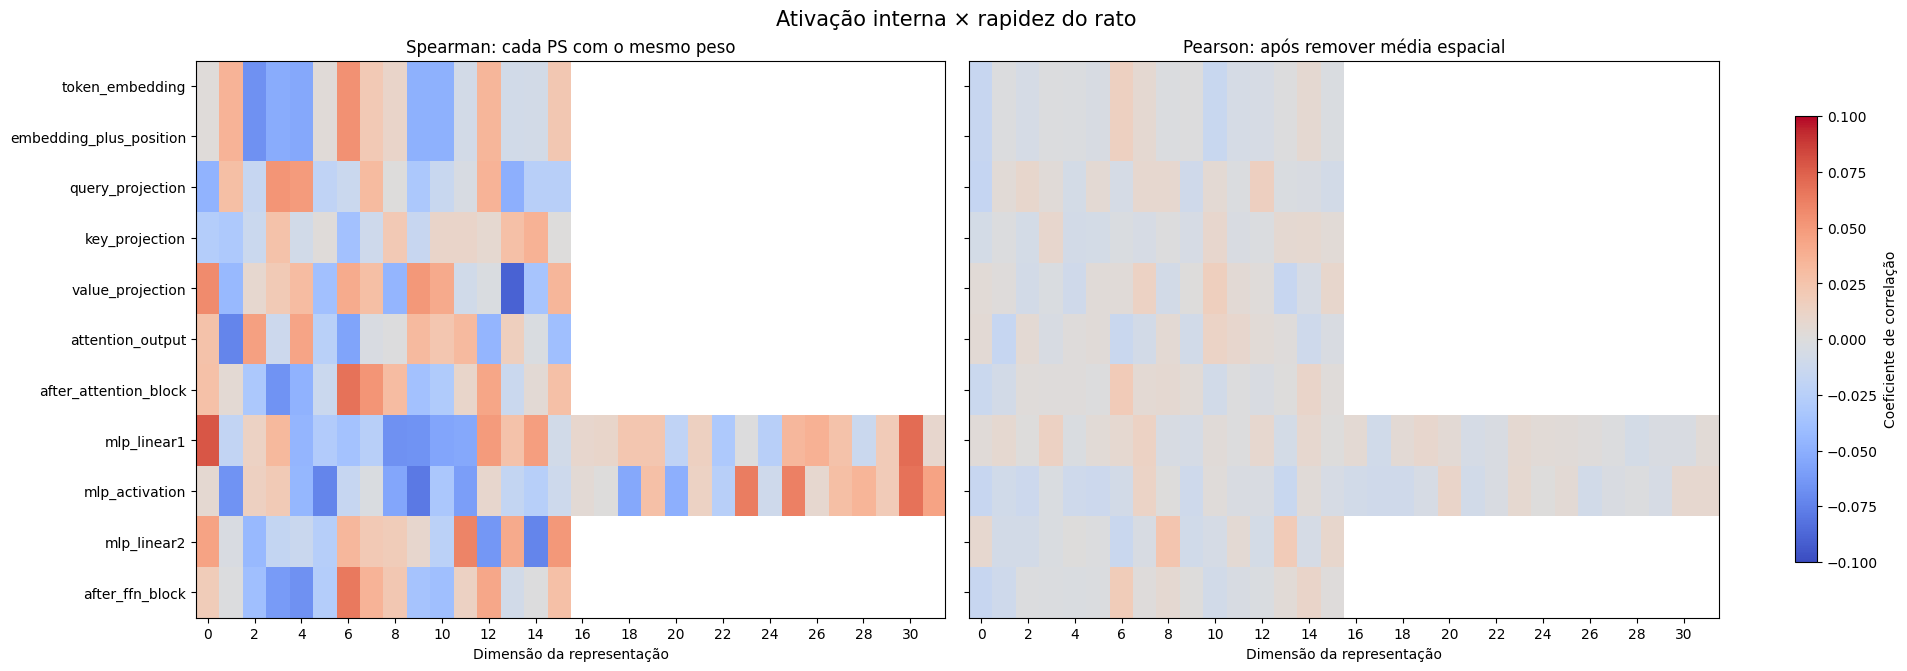

In [3]:
representation_order = list(dict.fromkeys(
    feature.rsplit('__d', 1)[0] for feature in feature_columns
))
metrics = [
    ('spearman_by_ps', 'Spearman: cada PS com o mesmo peso'),
    ('pearson_within_spatial_bin', 'Pearson: após remover média espacial'),
]
max_dim = max(correlations['dimension']) + 1
finite_values = correlations[[m[0] for m in metrics]].to_numpy(float)
color_limit = max(0.10, float(np.nanmax(np.abs(finite_values))))
fig, axes = plt.subplots(
    1, 2, figsize=(19, 6.6), sharey=True, constrained_layout=True
)
for ax, (metric, title) in zip(axes, metrics):
    matrix = np.full((len(representation_order), max_dim), np.nan)
    for row in correlations.itertuples():
        matrix[representation_order.index(row.representation), row.dimension] = getattr(row, metric)
    image = ax.imshow(
        np.ma.masked_invalid(matrix), origin='upper', aspect='auto',
        cmap='coolwarm', vmin=-color_limit, vmax=color_limit,
    )
    ax.set(
        title=title, xlabel='Dimensão da representação',
        xticks=np.arange(0, max_dim, 2),
        yticks=np.arange(len(representation_order)),
        yticklabels=representation_order,
    )
    ax.grid(False)
fig.colorbar(image, ax=axes, shrink=0.8, label='Coeficiente de correlação')
fig.suptitle('Ativação interna × rapidez do rato', fontsize=15)
fig.savefig(root / 'imgs/hardpos_ativacao_velocidade_correlacoes.png', dpi=150)
display(fig)
plt.close(fig)

## Dimensões com maior associação

A seleção abaixo usa a maior correlação absoluta por PS, com no máximo uma dimensão por representação. Cada ponto é um PS; o tamanho indica quantas amostras da trajetória o contêm. A linha vermelha mostra a média da ativação em faixas de rapidez. Para inspecionar outra dimensão, altere a lista selected_features usando a coluna feature do CSV de correlações.

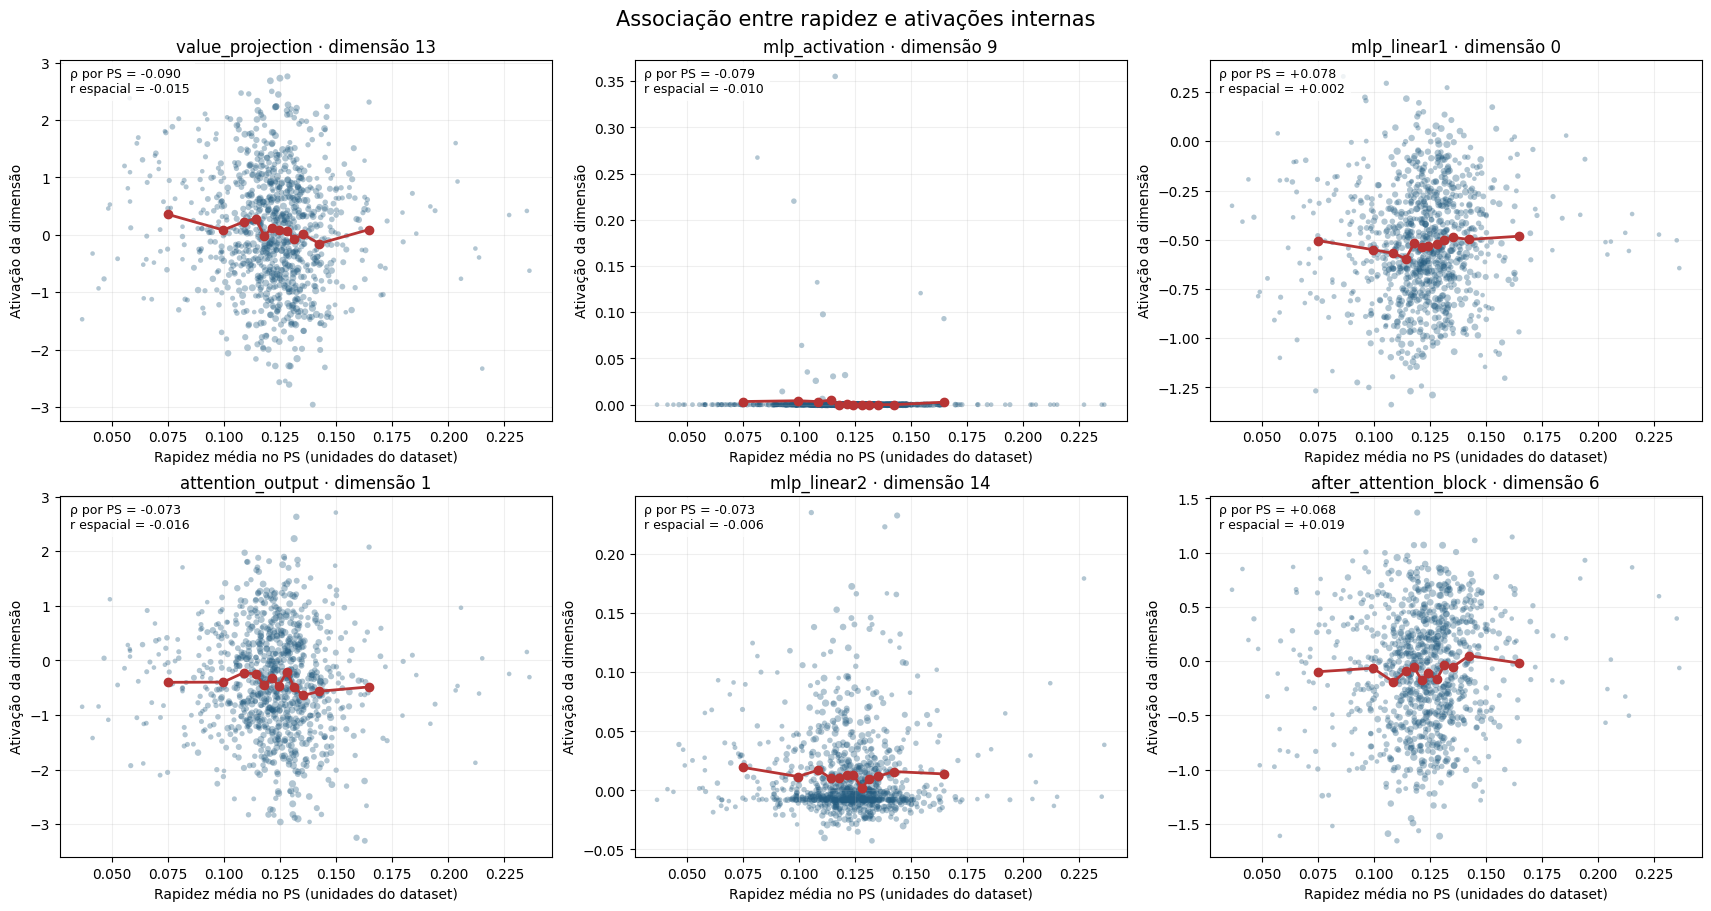

In [4]:
selected_features = (
    correlations.dropna(subset=['spearman_by_ps'])
    .drop_duplicates('representation')
    .head(6)['feature'].tolist()
)
if len(selected_features) != 6:
    raise ValueError('Não há seis representações com correlação definida.')

fig, axes = plt.subplots(2, 3, figsize=(17, 9), constrained_layout=True)
for ax, feature in zip(axes.flat, selected_features):
    row = correlations.set_index('feature').loc[feature]
    ax.scatter(
        per_ps['mean_speed'], per_ps[feature],
        s=8 + 3 * np.sqrt(per_ps['n_samples']),
        alpha=0.35, color='#245c80', edgecolors='none',
    )
    bins = pd.qcut(per_ps['mean_speed'], q=12, duplicates='drop')
    trend = per_ps.groupby(bins, observed=True).agg(
        speed=('mean_speed', 'mean'),
        activation=(feature, 'mean'),
    )
    ax.plot(
        trend['speed'], trend['activation'],
        color='#b73434', marker='o', linewidth=2,
    )
    ax.set(
        title=f'{row.representation} · dimensão {row.dimension}',
        xlabel='Rapidez média no PS (unidades do dataset)',
        ylabel='Ativação da dimensão',
    )
    stats_label = (f'ρ por PS = {row.spearman_by_ps:+.3f}' + chr(10)
                   + f'r espacial = {row.pearson_within_spatial_bin:+.3f}')
    ax.text(0.02, 0.98, stats_label, transform=ax.transAxes,
            va='top', ha='left', fontsize=9,
            bbox={'facecolor': 'white', 'alpha': 0.8, 'edgecolor': 'none'})
    ax.grid(alpha=0.2)
fig.suptitle('Associação entre rapidez e ativações internas', fontsize=15)
fig.savefig(root / 'imgs/hardpos_ativacao_velocidade_exemplos.png', dpi=150)
display(fig)
plt.close(fig)
